![Python Banner](../../Image/05_08_Quasi_Experiemnts.png)


# 8.5 Bayesian Causal Inference for Quasi-Experimental Data

A quasi-experiment identifies an effect only after the design is stated: parallel trends, a donor pool, a cutoff, an interruption date, or an instrument. The Bayesian step does not replace that design. It turns the estimator into a distribution of plausible effects.

PyCausalML does this without PyMC. For difference-in-differences, regression discontinuity, interrupted time series, instrumental variables, and synthetic control, the interval is a **Bayesian bootstrap** (Rubin, 1981): each draw reweights the rows with Dirichlet weights and refits the same estimator. For a linear conditional average treatment effect, `BayesianLinearCATE` uses a normal posterior on doubly robust scores.

A region of practical equivalence (ROPE) is a band of effects you would treat as too small to matter. `rope_probability` is the share of posterior draws inside that band.


## Overview

| Estimator | Design | What the interval describes |
|---|---|---|
| `BayesianLinearCATE` | Unconfounded binary treatment, linear CATE | Normal posterior of $a + X\beta$ on doubly robust scores |
| `DifferenceInDifferences` | Two groups, before and after | Bayesian bootstrap of $\tau$ in the interaction regression |
| `SyntheticControl` | One treated unit, many donors | Bayesian bootstrap of the pre-period match |
| `RegressionDiscontinuity` | Cutoff on a running variable | Bayesian bootstrap of the local linear jump |
| `InterruptedTimeSeries` | One series, known interruption | Bayesian bootstrap of the level shift |
| `InstrumentalVariable` | Endogenous treatment, instrument | Bayesian bootstrap of both stages |

The real datasets are the ones shipped with [CausalPy](https://causalpy.readthedocs.io/en/stable/).


## Implementation in Python

One simulated conditional effect, then five CausalPy datasets: banks (DiD), California Proposition 99 (synthetic control), the drinking-age series (RDD), England and Wales deaths (interrupted time series), and the Acemoglu, Johnson, and Robinson sample (IV).

## Set Up


In [1]:
import subprocess
import sys
from pathlib import Path

def _repo_root() -> Path:
    here = Path.cwd().resolve()
    for cand in [here, *here.parents]:
        if (cand / "pyproject.toml").is_file() and (cand / "src" / "pycausalml").is_dir():
            return cand
    raise FileNotFoundError(
        "PyCausalML repository was not found. Run this notebook from the repository."
    )

root = _repo_root()

try:
    import pycausalml  # noqa: F401
    print("PyCausalML ready.")
except ImportError:
    subprocess.check_call(
        [sys.executable, "-m", "pip", "install", "-q", "-e", f"{root}[plot]"],
    )
    print("PyCausalML installed.")
print("Repository:", root)


PyCausalML ready.
Repository: /home/zia207/Github/PyCausalML


In [2]:
%matplotlib inline
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from pycausalml import (
    BayesianLinearCATE,
    DifferenceInDifferences,
    InstrumentalVariable,
    InterruptedTimeSeries,
    RegressionDiscontinuity,
    SyntheticControl,
)
from pycausalml.bayesian_causal_inference import rope_probability

plt.rcParams["figure.dpi"] = 110
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")
print("Imported PyCausalML")


Imported PyCausalML


In [3]:
CAUSALPY_FILES = {
    "banks": "banks.csv",
    "covid": "deaths_and_temps_england_wales.csv",
    "drinking": "drinking.csv",
    "risk": "AJR2001.csv",
    "schoolReturns": "schoolingReturns.csv",
    "california_prop99": "california_prop99.csv",
}

def load_causalpy(name: str) -> pd.DataFrame:
    """Load a CausalPy example dataset.

    Uses causalpy.load_data when that package is installed. Otherwise reads
    the same CSV from the CausalPy GitHub data directory.
    """
    try:
        import causalpy as cp
        frame = cp.load_data(name)
        print(f"Loaded {name!r} with causalpy.load_data. Shape {frame.shape}.")
        return frame
    except ImportError:
        url = (
            "https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/"
            + CAUSALPY_FILES[name]
        )
        frame = pd.read_csv(url)
        print(f"CausalPy is not installed. Loaded {name!r} from")
        print(url)
        print("Install the package with: pip install 'pycausalml[causalpy]'")
        print(f"Shape {frame.shape}.")
        return frame


## Posterior draws

Every quasi-experimental estimator stores `draws_` and a `summary()` without those draws. The histogram is the posterior the interval is read from.


In [4]:
def show_draws(model, title, rope=None):
    draws = np.asarray(model.draws_, dtype=float)
    summary = model.summary()
    print(pd.Series({k: summary[k] for k in summary if k != "rope_probability"}).round(3))
    if rope is not None:
        print(f"ROPE {rope}: {rope_probability(draws, rope[0], rope[1]):.3f}")
    fig, ax = plt.subplots(figsize=(7.5, 3.4))
    ax.hist(draws, bins=30, color="#4C78A8", edgecolor="white")
    ax.axvline(model.effect_, color="#E45756", lw=2, label="Estimate")
    lo, hi = np.quantile(draws, [0.025, 0.975])
    ax.axvline(lo, color="gray", ls="--")
    ax.axvline(hi, color="gray", ls="--", label="95% interval")
    if rope is not None:
        ax.axvspan(rope[0], rope[1], color="#F2C14E", alpha=0.35, label="ROPE")
    ax.set_title(title)
    ax.legend()
    fig.tight_layout()
    plt.show()


## Part 1: Linear CATE on a simulation

The conditional effect is $1.5 + 0.8 x_0$. Treatment is binary and depends on $x_0$. `BayesianLinearCATE` cross-fits the outcome and the propensity, builds doubly robust scores, and puts a ridge-normal posterior on a linear function of $X$.


In [5]:
rng = np.random.default_rng(0)
n, p = 900, 4
X = rng.normal(size=(n, p))
propensity = 1 / (1 + np.exp(-(0.4 * X[:, 0])))
treatment = rng.binomial(1, propensity)
true_cate = 1.5 + 0.8 * X[:, 0]
outcome = 2 + 0.5 * X[:, 1] + treatment * true_cate + rng.normal(size=n)

cate = BayesianLinearCATE(prior_precision=1.0, n_splits=2, random_state=0)
cate.fit(X, treatment, outcome, feature_names=["x0", "x1", "x2", "x3"])
print("Average treatment effect from the doubly robust scores:")
print({k: round(v, 3) for k, v in cate.average_treatment_effect().items()})
print(f"Mean predicted CATE: {cate.predict(X).mean():.3f}")
print(f"Mean true CATE: {true_cate.mean():.3f}")

lo, hi = cate.credible_interval(X[:4])
preview = pd.DataFrame(
    {
        "x0": X[:4, 0],
        "predicted": cate.predict(X[:4]),
        "true": true_cate[:4],
        "ci_lower": lo,
        "ci_upper": hi,
    }
)
print(preview.round(3))


Average treatment effect from the doubly robust scores:
{'estimate': 1.491, 'std.err': 0.073}
Mean predicted CATE: 1.491
Mean true CATE: 1.495
      x0  predicted   true  ci_lower  ci_upper
0  0.126      1.598  1.601     1.437     1.759
1 -0.536      1.031  1.071     0.764     1.298
2 -0.704      0.914  0.937     0.672     1.156
3 -2.325     -0.543 -0.360    -0.924    -0.162


## Real-World Data

The series below is a real dataset shipped with [CausalPy](https://causalpy.readthedocs.io/en/stable/) (PyMC Labs), under the Apache License 2.0. The files live in [`causalpy/data`](https://github.com/pymc-labs/CausalPy/tree/main/causalpy/data).

```
@software{causalpy,
  author = {{PyMC Labs}},
  title = {CausalPy: Causal inference for quasi-experiments in Python},
  url = {https://github.com/pymc-labs/CausalPy},
  year = {2026}
}
```

PyCausalML fits the estimator. CausalPy is the data source. When CausalPy is installed, `causalpy.load_data` reads the packaged file. Otherwise the notebook reads the same CSV from that GitHub directory.

The five fits below use that collection. Each plot is the posterior of the design effect.


## Part 2: Difference-in-differences, banking closures

`banks` records banks in business in the 6th and 8th Federal Reserve districts, 1929–1934 (Richardson and Troost; Angrist and Pischke, *Mastering Metrics*). The 6th district is treated. The post period starts in 1931, matching CausalPy's intervention at 1930.5. The ROPE is a change of fewer than 5 banks, used here only as a scale for "small."


CausalPy is not installed. Loaded 'banks' from
https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/banks.csv
Install the package with: pip install 'pycausalml[causalpy]'
Shape (1878, 9).
estimate         20.750
ci_lower          6.673
ci_upper         30.995
posterior_mean   20.279
dtype: float64
ROPE (-5, 5): 0.007


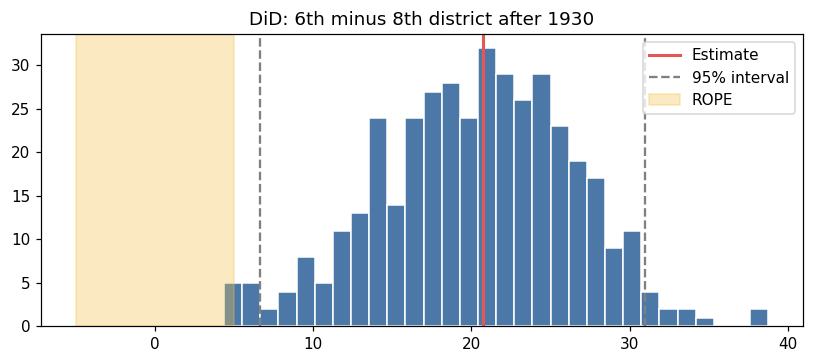

In [6]:
banks = load_causalpy("banks")
yearly = (
    banks.filter(items=["bib6", "bib8", "year"])
    .rename(columns={"bib6": "sixth", "bib8": "eighth"})
    .groupby("year")
    .median()
    .reset_index()
)
long = yearly.melt(id_vars="year", var_name="district", value_name="banks_open")
long["treated"] = (long["district"] == "sixth").astype(float)
long["post"] = (long["year"] >= 1931).astype(float)
did = DifferenceInDifferences(n_boot=400, rope=(-5, 5), random_state=0)
did.fit(long["banks_open"], long["treated"], long["post"])
show_draws(did, "DiD: 6th minus 8th district after 1930", rope=(-5, 5))


## Part 3: Synthetic control, California Proposition 99

`california_prop99` is annual per-capita cigarette sales, 1970–2000 (Abadie, Diamond, and Hainmueller, 2010). California adopted the tax in 1989. Donor weights are nonnegative and sum to one. The point estimate uses the original pre-period. Bootstrap draws that match California less well can move the gap, so the posterior mean need not equal that point estimate.


CausalPy is not installed. Loaded 'california_prop99' from
https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/california_prop99.csv
Install the package with: pip install 'pycausalml[causalpy]'
Shape (31, 40).


Largest donor weights:
Utah            0.394
Montana         0.232
Nevada          0.205
Connecticut     0.109
New Hampshire   0.045
Colorado        0.015
dtype: float64
estimate         -19.514
ci_lower         -41.708
ci_upper         -18.807
posterior_mean   -34.486
dtype: float64


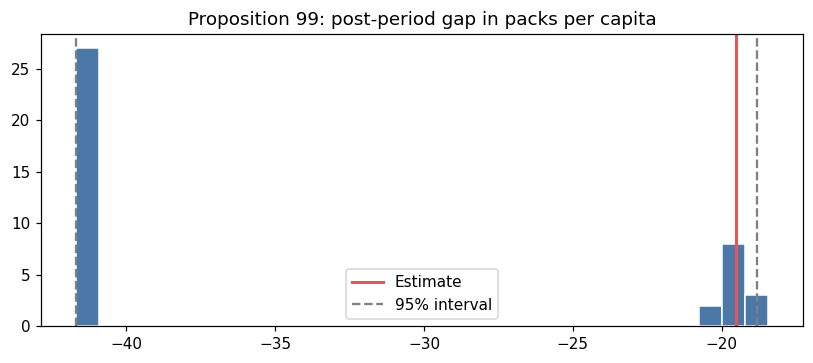

In [7]:
prop = load_causalpy("california_prop99").set_index("Year").sort_index().astype(float)
pre = prop.index < 1989
donors = prop.drop(columns=["California"])
scm = SyntheticControl(n_boot=40, random_state=0)
scm.fit(
    donors.loc[pre].to_numpy(),
    prop.loc[pre, "California"].to_numpy(),
    donors.loc[~pre].to_numpy(),
    prop.loc[~pre, "California"].to_numpy(),
)
weights = pd.Series(scm.weights_, index=donors.columns).sort_values(ascending=False)
print("Largest donor weights:")
print(weights.head(6).round(3))
show_draws(scm, "Proposition 99: post-period gap in packs per capita")


## Part 4: Regression discontinuity, minimum legal drinking age

`drinking` is the age-cell mortality series from the CausalPy regression-discontinuity example. The running variable is age. The cutoff is 21. The outcome is the all-cause death rate. The bandwidth is one year.


CausalPy is not installed. Loaded 'drinking' from
https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/drinking.csv
Install the package with: pip install 'pycausalml[causalpy]'
Shape (48, 20).


estimate          9.753
ci_lower          6.380
ci_upper         12.452
posterior_mean    9.780
dtype: float64


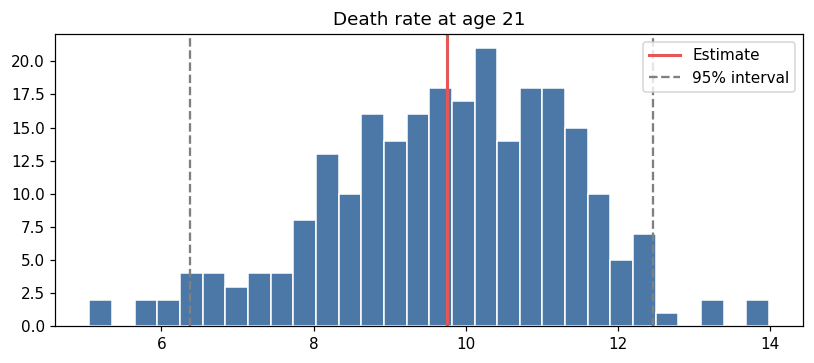

In [8]:
drinking = load_causalpy("drinking").rename(columns={"agecell": "age"})
rdd = RegressionDiscontinuity(cutoff=21, bandwidth=1.0, n_boot=250, random_state=0)
rdd.fit(drinking["age"].to_numpy(), drinking["all"].to_numpy())
show_draws(rdd, "Death rate at age 21")


## Part 5: Interrupted time series, deaths in England and Wales

`covid` is the CausalPy monthly series of deaths and temperature. `pre` is true through December 2019. Temperature and calendar month are removed using coefficients fit on the pre-period only, so the post-period level is not absorbed into the seasonal fit. `InterruptedTimeSeries` then estimates the level shift at the first post-period month. This is a design illustration. It is not an estimate of the pandemic's mortality toll: the interruption coincides with many other changes.


CausalPy is not installed. Loaded 'covid' from
https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/deaths_and_temps_england_wales.csv
Install the package with: pip install 'pycausalml[causalpy]'
Shape (197, 7).
Intervention index: 168 (2020-01-01)
estimate          7,643.669
ci_lower          1,795.500
ci_upper         18,780.559
posterior_mean    7,544.907
dtype: float64


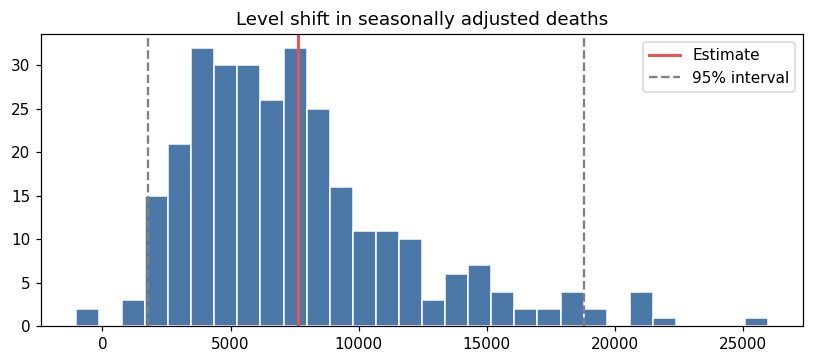

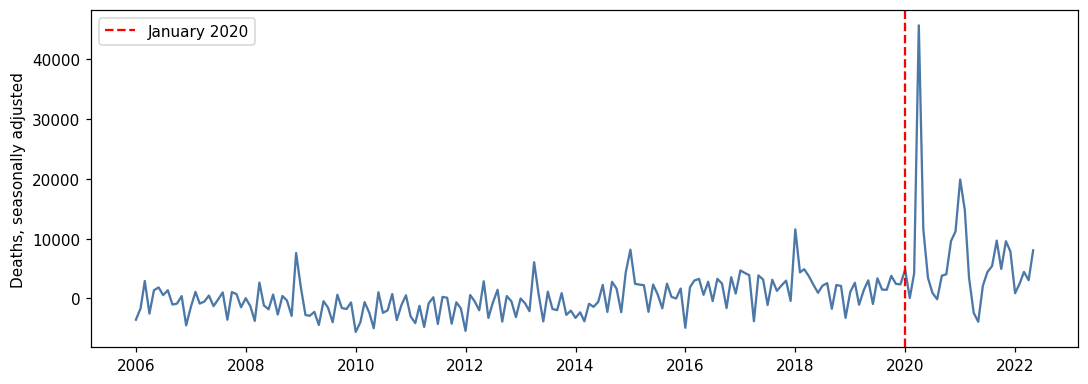

In [9]:
deaths = load_causalpy("covid")
deaths["date"] = pd.to_datetime(deaths["date"])
y = deaths["deaths"].to_numpy(float)
t = deaths["t"].to_numpy(float)
pre_mask = deaths["pre"].to_numpy(bool)
month = pd.get_dummies(deaths["month"], drop_first=True).to_numpy(float)
design = np.column_stack([np.ones(len(y)), deaths["temp"].to_numpy(float), month])
season = np.linalg.lstsq(design[pre_mask], y[pre_mask], rcond=None)[0]
residual = y - design @ season
intervention = float(t[~pre_mask][0])
its = InterruptedTimeSeries(n_boot=300, random_state=0)
its.fit(t, residual, intervention)
print(f"Intervention index: {intervention:.0f} ({deaths.loc[~pre_mask, 'date'].iloc[0].date()})")
show_draws(its, "Level shift in seasonally adjusted deaths")

fig, ax = plt.subplots(figsize=(10, 3.6))
ax.plot(deaths["date"], residual, color="#4C78A8")
ax.axvline(deaths.loc[~pre_mask, "date"].iloc[0], color="red", ls="--", label="January 2020")
ax.set_ylabel("Deaths, seasonally adjusted")
ax.legend()
fig.tight_layout()
plt.show()


## Part 6: Instrumental variables, colonial origins

`risk` is the Acemoglu, Johnson, and Robinson (2001) country sample (`AJR2001.csv`). Log GDP per capita is the outcome, protection against expropriation (`risk`) is the endogenous treatment, and log settler mortality (`logmort0`) is the instrument. The exclusion restriction — settler mortality affects present income only through institutions — is contested. The posterior below is the 2SLS coefficient under that assumption, not a settled answer.


CausalPy is not installed. Loaded 'risk' from
https://raw.githubusercontent.com/pymc-labs/CausalPy/main/causalpy/data/AJR2001.csv
Install the package with: pip install 'pycausalml[causalpy]'
Shape (64, 31).
estimate         0.929
ci_lower         0.709
ci_upper         1.441
posterior_mean   0.951
dtype: float64


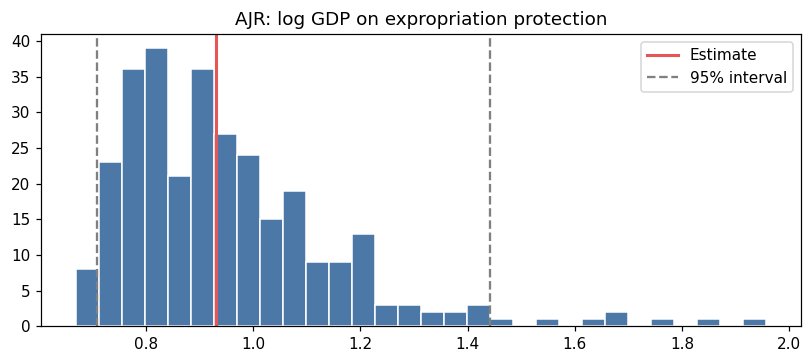

In [10]:
ajr = load_causalpy("risk").dropna(subset=["loggdp", "risk", "logmort0"])
iv = InstrumentalVariable(n_boot=300, random_state=0)
iv.fit(ajr["loggdp"].to_numpy(), ajr["risk"].to_numpy(), ajr["logmort0"].to_numpy())
show_draws(iv, "AJR: log GDP on expropriation protection")


## Reading the summaries together

| Dataset | Design | Estimator |
|---|---|---|
| Simulated CATE | Unconfoundedness, linear effect | `BayesianLinearCATE` |
| Banks | Parallel trends across two Federal Reserve districts | `DifferenceInDifferences` |
| Proposition 99 | A weighted donor pool matches California before 1989 | `SyntheticControl` |
| Drinking age | Units just above and below 21 are comparable | `RegressionDiscontinuity` |
| England and Wales deaths | The pre-period seasonality would have continued | `InterruptedTimeSeries` |
| AJR 2001 | Settler mortality affects income only through institutions | `InstrumentalVariable` |

A narrow interval does not repair a bad design. Check the pre-trend, the pre-period synthetic fit, the density at the cutoff, or the first stage before reading the posterior as a causal effect.


## Scientific Terminology

Plain-language definitions for the terms in this tutorial are in the [scientific terminology glossary](../00-scientific-terminology-glossary.qmd).
